In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.losses import SparseCategoricalCrossentropy
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.optimizers import Adam, SGD, RMSprop, Adagrad, Adadelta, Nadam
from sklearn.model_selection import train_test_split

In [ ]:
# Load the mnist_corrupted dataset
data, info = tfds.load('mnist_corrupted/shot_noise', with_info=True, as_supervised=True)

train_data, test_data = data['train'], data['test']

# Preprocess the data
def preprocess_data(data):
    images = []
    labels = []
    for image, label in tfds.as_numpy(data):
        images.append(image / 255.0)  # Scale image pixel values by dividing by 255.0
        labels.append(label)
    return images, labels

x_train, y_train = preprocess_data(train_data)
x_test, y_test = preprocess_data(test_data)

print("=============y_train=============")
print(tf.shape(y_train), "records")
print(y_train[:5])

x_train = [x / 255.0 for x in x_train]
x_test = [x / 255.0 for x in x_test]

print("=============x_train=============")
print(tf.shape(x_train))
print("=============x_train element 0=============")
print(x_train[0])

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...:   0%|          | 0/60000 [00:00<?, ? examples/s]

Shuffling /root/tensorflow_datasets/mnist_corrupted/shot_noise/incomplete.XOCSUN_1.0.0/mnist_corrupted-train.t…

Generating test examples...:   0%|          | 0/10000 [00:00<?, ? examples/s]

Shuffling /root/tensorflow_datasets/mnist_corrupted/shot_noise/incomplete.XOCSUN_1.0.0/mnist_corrupted-test.tf…

Dataset mnist_corrupted downloaded and prepared to /root/tensorflow_datasets/mnist_corrupted/shot_noise/1.0.0. Subsequent calls will reuse this data.
=============y_train=============
tf.Tensor([60000], shape=(1,), dtype=int32) records
[4, 1, 0, 7, 8]
=============x_train=============
tf.Tensor([60000    28    28     1], shape=(4,), dtype=int32)
=============x_train element 0=============
[[[0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]]

 [[0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0.        ]
  [0. 

In [ ]:
print( x_train[0].shape)

(28, 28, 1)


The mnist_corrupted dataset has three dimentsions, where the last dimension of 1 indicates its greyscale channel, which is not a necessary attribute for this model.  Therefore, the channel dimension is romved to reduce the computational complexity.  

In [ ]:
# remove the channel dimension
x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

x_train = x_train.squeeze()
x_test = x_test.squeeze()

print(x_train[0])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [ ]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10)
])


/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
print("=============first element of x_train (29 rows)=============")
print(x_train[:1])

predictions = model(x_train[:1]).numpy()
print("=============untrained output of first training set input=============")
print(predictions)

=============first element of x_train (29 rows)=============
[[[0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.        ]
  [0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.        ]
  [0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.         0.         0.
   0.         0.         0.         0.        ]
  [0.         0.         0.         0.         0.         0.
  

In [ ]:
tf.nn.softmax(predictions).numpy()

array([[0.10001802, 0.10014778, 0.10013992, 0.09995438, 0.1001573 ,
        0.09992293, 0.09991389, 0.09984753, 0.09990948, 0.09998874]],
      dtype=float32)

In [ ]:
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
loss_fn(y_train[:1], predictions).numpy()

2.3040621

### Training with Adam Optimizer

In [ ]:
model.compile(optimizer='adam',
              loss=loss_fn,
              metrics=['accuracy'])
model.fit(x_train, y_train, epochs=5)
model.evaluate(x_test,  y_test, verbose=2)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.4967 - loss: 1.7989
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8054 - loss: 0.6879
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8558 - loss: 0.5113
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8728 - loss: 0.4431
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8782 - loss: 0.4081
313/313 - 1s - 2ms/step - accuracy: 0.8975 - loss: 0.3491


[0.3490568697452545, 0.8974999785423279]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


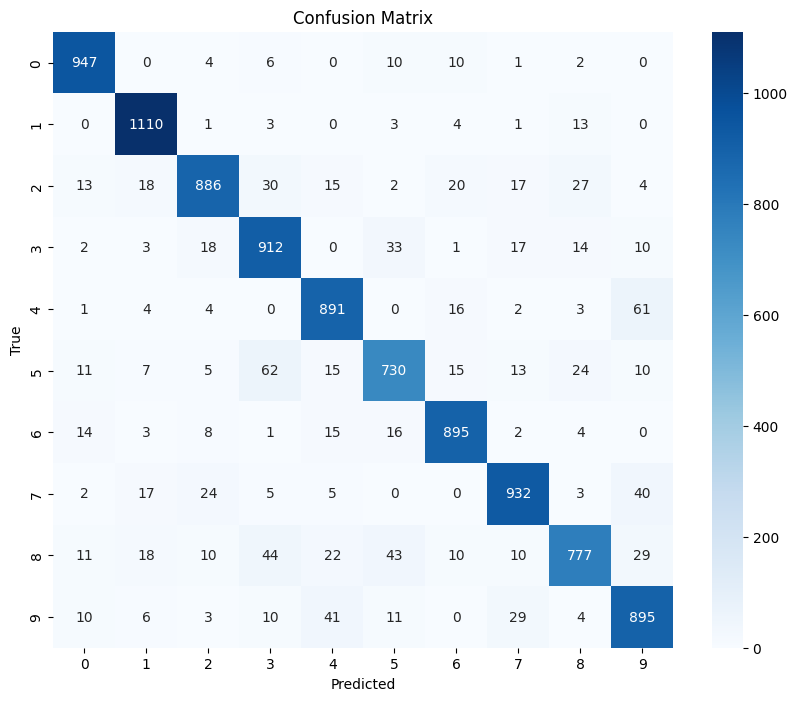

In [ ]:
# Confusion Matrix
y_pred = model.predict(x_test)
y_pred_classes = y_pred.argmax(axis=1)

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

Comment: this model is most accurate for recognizing '1', and least accurate when recognizing '5'

In [ ]:
y_pred = model.predict(x_test).argmax(axis=1)
y_true = y_test

classes = np.unique(y_true)
per_class_accuracy = {}

for cls in classes:
    indices = np.where(y_true == cls)
    # Calculate accuracy
    correct_predictions = np.sum(y_pred[indices] == y_true[indices])
    total_predictions = len(indices[0])
    accuracy = correct_predictions / total_predictions
    per_class_accuracy[cls] = accuracy

for cls, acc in per_class_accuracy.items():
    print(f"Accuracy {cls}: {acc:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy 0: 0.9663
Accuracy 1: 0.9780
Accuracy 2: 0.8585
Accuracy 3: 0.9030
Accuracy 4: 0.9073
Accuracy 5: 0.8184
Accuracy 6: 0.9342
Accuracy 7: 0.9066
Accuracy 8: 0.7977
Accuracy 9: 0.8870


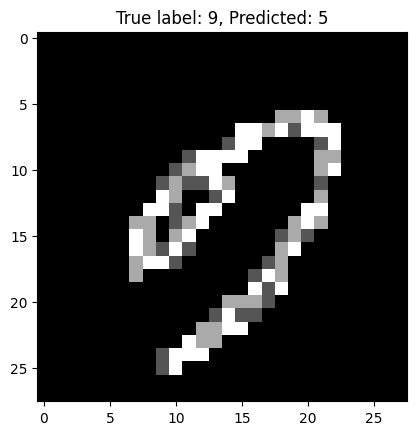

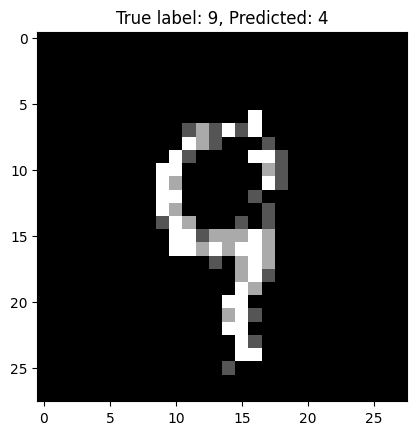

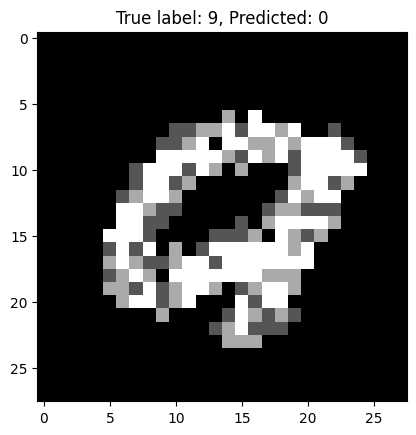

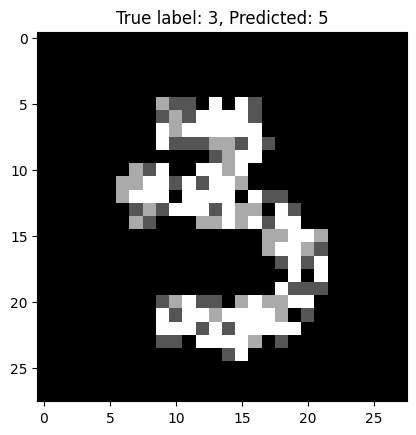

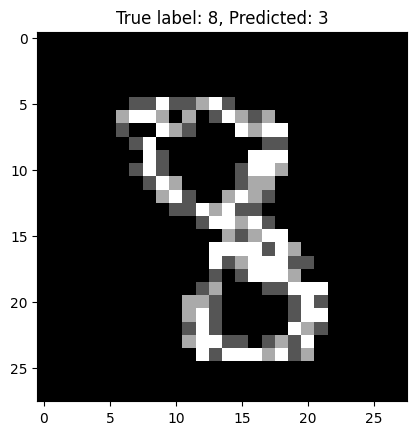

In [ ]:
# examine the misclassifications
misclassified_indices = [i for i, (pred, true) in enumerate(zip(y_pred, y_test)) if pred != true and true in [3, 5, 8, 9]]
for i in misclassified_indices[:5]:
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"True label: {y_test[i]}, Predicted: {y_pred[i]}")
    plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)
def build_and_evaluate_model(units):
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(units, activation='relu'),
        Dropout(0.2),
        Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.01),  # Pre-determined learning rate
        loss=SparseCategoricalCrossentropy(from_logits=False),
        metrics=['accuracy']
    )
    history = model.fit(x_train, y_train, epochs=5, validation_data=(x_val, y_val), verbose=0)
    val_accuracy = history.history['val_accuracy'][-1]  # Take the last validation accuracy value
    return val_accuracy

# Initial number of units
units = 64
best_units = units
best_val_accuracy = build_and_evaluate_model(units)

# Doubling or halving loop
while True:
    new_units = units * 2
    new_val_accuracy = build_and_evaluate_model(new_units)
    if new_val_accuracy > best_val_accuracy:
        best_val_accuracy = new_val_accuracy
        best_units = new_units
        units = new_units
        continue  # Keep doubling if performance improves
    new_units = units // 2
    new_val_accuracy = build_and_evaluate_model(new_units)
    if new_val_accuracy > best_val_accuracy:
        best_val_accuracy = new_val_accuracy
        best_units = new_units
        units = new_units
    else:
        break  # Stop if neither doubling nor halving improves performance

print(f"The optimal number of units found is: {best_units} with a validation accuracy of: {best_val_accuracy:.4f}")

The optimal number of units found is: 512 with a validation accuracy of: 0.9413


In [ ]:
def build_model(hp):
    model = Sequential()
    model.add(Flatten(input_shape=(28, 28)))
    # Use doubling/halving logic for tuning the number of neurons
    base_units = 512  # Optimal number of neurons identified above
    best_units = base_units
    best_val_accuracy = 0

    while True:
        model.add(Dense(best_units, activation='relu'))
        model.add(Dropout(hp.Float('dropout', min_value=0.1, max_value=0.5, step=0.05)))
        model.add(Dense(10, activation='softmax'))
        model.compile(
            optimizer=Adam(learning_rate=hp.Choice('learning_rate', values=[0.01, 0.001, 0.0005, 0.0001])),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
        history = model.fit(x_train, y_train, epochs=5, validation_data=(x_val, y_val), verbose=0)
        val_accuracy = history.history['val_accuracy'][-1]
        # Doubling/halving logic
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_units *= 2
        else:
            best_units //= 2
            if best_units < base_units:
                break  # Stop if halving goes below the initial base units
    return model

# Instantiate the tuner
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,  # Number of hyperparameter configurations to try
    directory='my_dir',
    project_name='mnist_tuning'
)

# Perform the hyperparameter search
tuner.search(x_train, y_train, epochs=5, validation_data=(x_val, y_val))

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"The optimal dropout rate is: {best_hps.get('dropout')}")
print(f"The optimal learning rate is: {best_hps.get('learning_rate')}")

Reloading Tuner from my_dir/mnist_tuning/tuner0.json
The optimal dropout rate is: 0.15000000000000002
The optimal learning rate is: 0.01


In [ ]:
# test the hyperparameter above
model2 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(512, activation='relu'),  # number of neuron 512
    Dropout(0.15),  # Dropout layer with rate 0.15
    Dense(10, activation='softmax')
])

model2.compile(
    optimizer=Adam(learning_rate=0.01),
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

model2.fit(x_train, y_train, epochs=5)

model2.evaluate(x_val, y_val, verbose=2)

Epoch 1/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6743 - loss: 1.0621
Epoch 2/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8919 - loss: 0.3566
Epoch 3/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9160 - loss: 0.2725
Epoch 4/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9265 - loss: 0.2339
Epoch 5/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9450 - loss: 0.1872
192/192 - 0s - 2ms/step - accuracy: 0.9362 - loss: 0.2155


[0.215457022190094, 0.9361979365348816]

## Testing alternative optimizers

In [ ]:
optimizers = [Adam(), SGD(), RMSprop(), Adagrad(), Adadelta(), Nadam()]
optimizer_names = ['Adam', 'SGD', 'RMSprop', 'Adagrad', 'Adadelta', 'Nadam']
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)
# Function to build and evaluate the model
def build_and_evaluate_model(optimizer):
    model3 = Sequential([
      Flatten(input_shape=(28, 28)),
      Dense(512, activation='relu'),  # number of neuron 512
      Dropout(0.15),  # Dropout layer with rate 0.15
      Dense(10, activation='softmax')
  ])
    model3.compile(
      optimizer=Adam(learning_rate=0.01),
      loss=SparseCategoricalCrossentropy(from_logits=False),
      metrics=['accuracy']
  )
    # Train and evaluate the model
    history = model3.fit(x_train, y_train, epochs=5, validation_data=(x_val, y_val), verbose=0)
    val_accuracy = history.history['val_accuracy'][-1]  # Take the last validation accuracy value
    return val_accuracy

# Testing different optimizers
best_optimizer = None
best_val_accuracy = 0
for optimizer, name in zip(optimizers, optimizer_names):
    print(f"Testing optimizer: {name}")
    val_accuracy = build_and_evaluate_model(optimizer)
    print(f"Validation accuracy with {name}: {val_accuracy:.4f}")
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_optimizer = name

print(f"The best optimizer found is: {best_optimizer} with a validation accuracy of: {best_val_accuracy:.4f}")

Testing optimizer: Adam
Validation accuracy with Adam: 0.9422
Testing optimizer: SGD
Validation accuracy with SGD: 0.9341
Testing optimizer: RMSprop
Validation accuracy with RMSprop: 0.9386
Testing optimizer: Adagrad
Validation accuracy with Adagrad: 0.9383
Testing optimizer: Adadelta
Validation accuracy with Adadelta: 0.9382
Testing optimizer: Nadam
Validation accuracy with Nadam: 0.9351
The best optimizer found is: Adam with a validation accuracy of: 0.9422


## Adding addiitonal layers

In [ ]:
model4 = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.15),
    Dense(512, activation='relu'),  # additional layer
    Dropout(0.15),
    Dense(10, activation='softmax')
])

model4.compile(
    optimizer=Adam(learning_rate=0.01),
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

model4.fit(x=x_train, y=y_train, validation_data=(x_val,y_val),epochs=5)

Epoch 1/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.6275 - loss: 1.0446 - val_accuracy: 0.8921 - val_loss: 0.3374
Epoch 2/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.8900 - loss: 0.3438 - val_accuracy: 0.9201 - val_loss: 0.2636
Epoch 3/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9167 - loss: 0.2595 - val_accuracy: 0.9215 - val_loss: 0.2497
Epoch 4/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.9287 - loss: 0.2243 - val_accuracy: 0.9357 - val_loss: 0.2105
Epoch 5/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.9397 - loss: 0.1908 - val_accuracy: 0.9372 - val_loss: 0.1993


## Adding Regularizer

In [ ]:
from tensorflow.keras.regularizers import l2

model5 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(512, activation='relu', kernel_regularizer=l2(0.0001)),
    Dropout(0.15),
    Dense(10, activation='softmax')
])
model5.compile(
    optimizer=Adam(learning_rate=0.01),
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

model5.fit(x_train, y_train, epochs=5)
model5.evaluate(x_val, y_val, verbose=2)

Epoch 1/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.1380 - loss: 2.3093
Epoch 2/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.3251 - loss: 2.1095
Epoch 3/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.4646 - loss: 1.8697
Epoch 4/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.5282 - loss: 1.6949
Epoch 5/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5701 - loss: 1.5761
192/192 - 0s - 2ms/step - accuracy: 0.6554 - loss: 1.4084


[1.408402442932129, 0.6554362177848816]

In [ ]:
model5_ = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.0001)),  # L2 regularization
    Dropout(0.15),
    Dense(10, activation='softmax')
])
model5_.compile(
    optimizer=Adam(learning_rate=0.01),
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

model5_.fit(x_train, y_train, epochs=5)
model5_.evaluate(x_val, y_val, verbose=2)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 35s 5ms/step - accuracy: 0.5113 - loss: 1.7756
Epoch 2/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7976 - loss: 1.0278
Epoch 3/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8175 - loss: 0.8935
Epoch 4/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8253 - loss: 0.8292
Epoch 5/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8274 - loss: 0.7886
192/192 - 0s - 2ms/step - accuracy: 0.8268 - loss: 0.7759


[0.7759098410606384, 0.8268229365348816]

In [ ]:
model5_2 = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.0001)),  # L2 regularization
    Dropout(0.15),
    Dense(10, activation='softmax')
])
model5_2.compile(
    optimizer=Adam(learning_rate=0.01),
    loss=SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

model5_2.fit(x_train, y_train, epochs=5)
model5_2.evaluate(x_val, y_val, verbose=2)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4741 - loss: 1.8430
Epoch 2/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7775 - loss: 1.0964
Epoch 3/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8097 - loss: 0.9246
Epoch 4/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8260 - loss: 0.8418
Epoch 5/5
768/768 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8299 - loss: 0.7894
192/192 - 0s - 2ms/step - accuracy: 0.8507 - loss: 0.7105


[0.7105035185813904, 0.8507487177848816]

Adding a regularizer did not improve result

## Increasing epochs

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

def build_and_train_model():
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(512, activation='relu'),
        Dropout(0.15),
        Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.01),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    # Early stopping callback to find optimal epochs
    early_stopping = EarlyStopping(
        monitor='val_accuracy',
        patience=3,  # Number of epochs with no improvement to stop training
        restore_best_weights=True  # Restore the weights from the best epoch
    )
    # Train the model with a high number of epochs and early stopping
    history = model.fit(
        x_train, y_train,
        epochs=50,  # High number of epochs to allow training to continue as long as beneficial
        validation_data=(x_val, y_val),
        callbacks=[early_stopping],
        verbose=1
    )
    optimal_epochs = len(history.history['accuracy'])
    print(f"The optimal number of epochs is: {optimal_epochs}")

    model.evaluate(x_val, y_val, verbose=2)

build_and_train_model()

Epoch 1/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.6537 - loss: 1.0900 - val_accuracy: 0.8812 - val_loss: 0.3848
Epoch 2/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8920 - loss: 0.3524 - val_accuracy: 0.9108 - val_loss: 0.2903
Epoch 3/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9107 - loss: 0.2873 - val_accuracy: 0.9251 - val_loss: 0.2495
Epoch 4/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9285 - loss: 0.2365 - val_accuracy: 0.9329 - val_loss: 0.2284
Epoch 5/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9389 - loss: 0.1921 - val_accuracy: 0.9334 - val_loss: 0.2042
Epoch 6/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9511 - loss: 0.1594 - val_accuracy: 0.9417 - val_loss: 0.2024
Epoch 7/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9554 - loss: 0.1470 - val_accuracy: 0.9442 - val_loss: 0.1800
Epoch 8/50
768/768 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9632 - loss: 0.1221 - val_accuracy: 